# Phase 1: Data understanding (C-MAPSS FD001)

**Goal.** Confirm the data structure, decide which columns to keep, build the RUL labels and justify the RUL cap, using the *training* data only.

**Run it.** Put the NASA files (`train_FD001.txt`, `test_FD001.txt`, `RUL_FD001.txt`) in `data/`, or set the environment variable `CMAPSS_DATA_DIR`. Then *Run All*. Everything is seeded.

**Scope.** FD001 has one operating condition and one fault mode (HPC degradation), so the screening below is valid for FD001/FD003 only (see `cmapss/features.py`).

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the repo root (the folder containing src/cmapss) so this runs from anywhere inside the repo.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "cmapss").is_dir())
sys.path.insert(0, str(ROOT / "src"))
DATA_DIR = Path(os.environ.get("CMAPSS_DATA_DIR", ROOT / "data"))

from cmapss.loader import load_subset, add_rul, SENSOR_COLUMNS, SETTING_COLUMNS, SENSOR_INFO
from cmapss.features import select_columns, degradation_onset

plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
SEED = 0
ALL_COLS = SETTING_COLUMNS + SENSOR_COLUMNS
print("data directory:", DATA_DIR)

data directory: /mnt/user-data/uploads


## 1. Load and validate

`load_subset` checks every file before returning it: 26 numeric columns, no NaN/inf, units numbered 1..N, cycles exactly 1..n within each unit, engine counts, and one true RUL per test engine. If any check fails it raises `DataValidationError` instead of returning bad data (these checks are covered by `tests/test_loader.py`).

In [2]:
data = load_subset("FD001", DATA_DIR)   # raises DataValidationError if any file is malformed or the counts are off
train, test, test_rul = data.train, data.test, data.test_rul

summary = pd.DataFrame(
    {"engines": [train.unit.nunique(), test.unit.nunique()],
     "rows": [len(train), len(test)],
     "columns": [train.shape[1], test.shape[1]]},
    index=["train", "test"],
)
display(summary)
print("true RUL values supplied:", len(test_rul))

true RUL values supplied: 100


,engines,rows,columns
train,100,20631,26
test,100,13096,26


test engines with fewer than 40 observed cycles: 4
test engines with true RUL > 125: 11


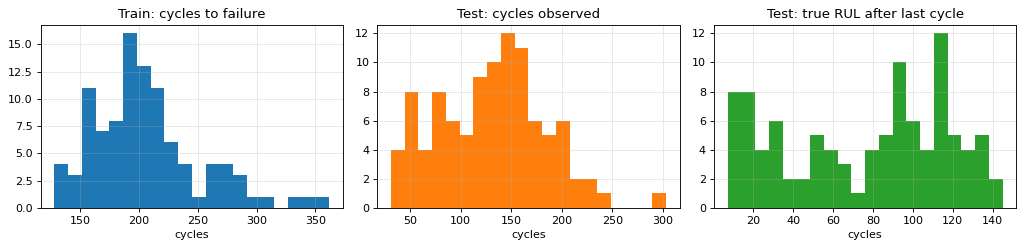

,train life,test observed,test true RUL
min,128.0,31.0,7.0
25%,177.0,88.8,32.8
50%,199.0,133.5,86.0
75%,229.2,164.2,112.2
max,362.0,303.0,145.0


In [3]:
life = train.groupby("unit").cycle.max()          # train: cycles until failure
test_len = test.groupby("unit").cycle.max()       # test: cycles observed before the cut-off

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].hist(life, bins=20);                 ax[0].set(title="Train: cycles to failure", xlabel="cycles")
ax[1].hist(test_len, bins=20, color="C1"); ax[1].set(title="Test: cycles observed", xlabel="cycles")
ax[2].hist(test_rul, bins=20, color="C2"); ax[2].set(title="Test: true RUL after last cycle", xlabel="cycles")
plt.tight_layout(); plt.show()

stats = pd.DataFrame({"train life": life.describe(), "test observed": test_len.describe(), "test true RUL": test_rul.describe()}).round(1)
display(stats.loc[["min", "25%", "50%", "75%", "max"]])
print("test engines with fewer than 40 observed cycles:", int((test_len < 40).sum()))
print("test engines with true RUL > 125:", int((test_rul > 125).sum()))

**Findings**
- 100 training engines (run to failure) and 100 test engines (truncated before failure), 26 columns each, plus 100 true RUL values: this matches the readme.
- Training lifetimes run from 128 to 362 cycles (median 199). Test engines are observed for 31 to 303 cycles (median 133.5), and their true RUL after the cut-off ranges from 7 to 145 (median 86).
- **Design consequence 1:** the shortest observed test engine has 31 cycles, so a window of up to 30 cycles needs no padding. A longer window needs an explicit rule for short engines (pad or reject), which must be documented.
- **Design consequence 2:** 11 test engines have a true RUL above 125. A model trained on a target capped at 125 cannot predict these exactly (see section 4).

## 2. Sensors against cycle

Eight engines (chosen with a fixed seed, the same in every panel), all 3 operational settings and 21 sensors. Units and symbols follow Table 2 of Saxena et al. (2008); the mapping of `s1`..`s21` to that table is the usual convention rather than something the readme states.

engines shown: [2, 5, 8, 26, 30, 49, 60, 80]


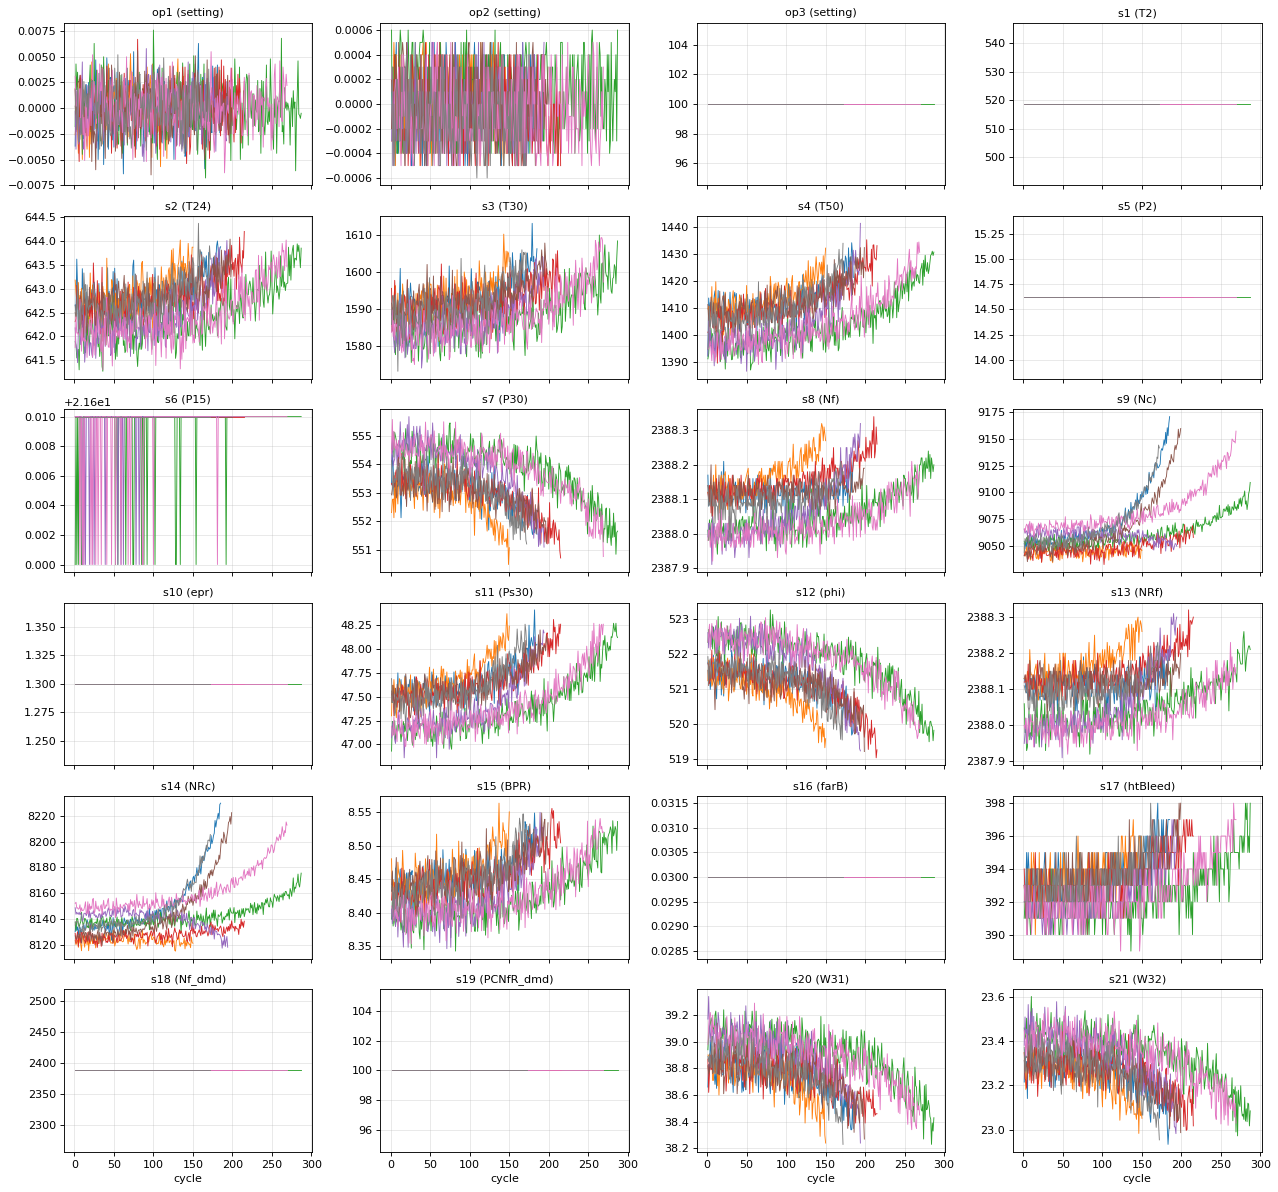

In [4]:
rng = np.random.default_rng(SEED)
show_units = rng.choice(train.unit.unique(), size=8, replace=False)   # same 8 engines in every panel

fig, axes = plt.subplots(6, 4, figsize=(16, 15), sharex=True)
for ax, col in zip(axes.ravel(), ALL_COLS):
    for u in show_units:
        g = train[train.unit == u]
        ax.plot(g.cycle, g[col], lw=0.8)
    symbol = SENSOR_INFO[col][0] if col in SENSOR_INFO else "setting"
    ax.set_title(f"{col} ({symbol})", fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel("cycle")
plt.tight_layout(); plt.show()
print("engines shown:", sorted(int(u) for u in show_units))

**Observations**
- **Seven columns are flat lines:** `op3`, `s1`, `s5`, `s10`, `s16`, `s18`, `s19`.
- `op1` and `op2` are only noise around zero (a single operating condition), and `s6` just flips between two values (21.60 and 21.61), which looks like quantisation rather than signal.
- **Fourteen sensors drift in a consistent direction over life:** rising for `s2, s3, s4, s8, s9, s11, s13, s14, s15, s17` and falling for `s7, s12, s20, s21`.
- **Engines start at different levels** (clear in `s2`-`s4`, `s8`, `s9`, `s11`-`s15`). This fits the initial wear and manufacturing variation described in the paper, and it is not a fault.
- The drift is slow early and speeds up near failure (see `s9`, `s14`), which is consistent with the exponential damage model in the paper. Noise is large relative to the early trend for several sensors, so smoothing or windowing will matter.

## 3. Constant and near-constant columns

A variance threshold alone is awkward here, because raw variance depends on the unit of each sensor (`s9` is in thousands of rpm, `s16` is 0.03). So the screening has two steps, implemented in `select_columns`:

1. **Zero variance:** drop columns with a single distinct value.
2. **No consistent trend:** for each engine, compute the Spearman correlation between the column and `cycle`; take the median of its absolute value over engines (the *trend strength*, scale-free) and drop columns below a threshold of 0.3.

The threshold is chosen from the data in the plot below, not copied from a paper.

In [5]:
kept, report = select_columns(train, ALL_COLS, min_trend=0.3)
display(report.round(3))
print("kept   (%d):" % len(kept), kept)
print("dropped (%d):" % (len(ALL_COLS) - len(kept)), [c for c in ALL_COLS if c not in kept])

kept   (14): ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
dropped (10): ['op1', 'op2', 'op3', 's1', 's5', 's6', 's10', 's16', 's18', 's19']


,n_unique,std,trend_strength,kept,reason
column,,,,,
op1,158,0.002,0.044,False,no consistent trend (< 0.3)
op2,13,0.000,0.044,False,no consistent trend (< 0.3)
op3,1,0.000,0.000,False,constant (zero variance)
s1,1,0.000,0.000,False,constant (zero variance)
s2,310,0.500,0.671,True,kept
s3,3012,6.131,0.637,True,kept
s4,4051,9.001,0.784,True,kept
s5,1,0.000,0.000,False,constant (zero variance)
s6,2,0.001,0.068,False,no consistent trend (< 0.3)


Largest trend among dropped (non-constant) columns: 0.068; smallest among kept: 0.637
Any threshold in that gap gives the same selection.


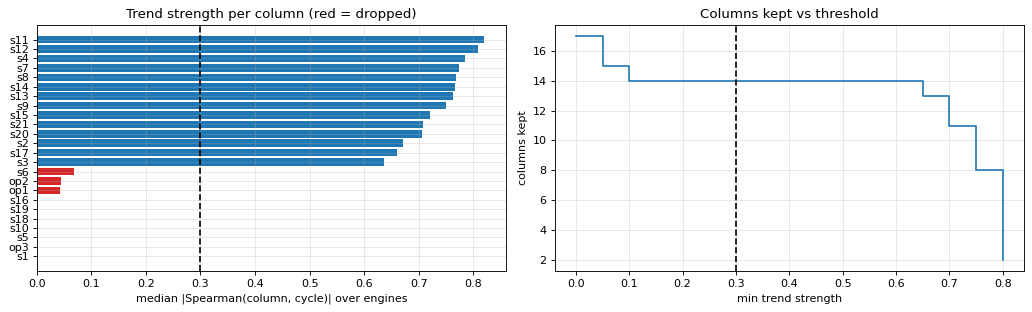

In [6]:
varying = report.n_unique > 1
ts = report.trend_strength.sort_values()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].barh(ts.index, ts.values, color=["C0" if report.kept[c] else "C3" for c in ts.index])
ax[0].axvline(0.3, color="k", ls="--"); ax[0].set(title="Trend strength per column (red = dropped)", xlabel="median |Spearman(column, cycle)| over engines")

thresholds = np.round(np.arange(0.0, 0.85, 0.05), 2)
counts = [int(((report.trend_strength >= t) & varying).sum()) for t in thresholds]
ax[1].step(thresholds, counts, where="post"); ax[1].axvline(0.3, color="k", ls="--")
ax[1].set(title="Columns kept vs threshold", xlabel="min trend strength", ylabel="columns kept")
plt.tight_layout(); plt.show()

gap = report.loc[varying]
lo = gap.trend_strength[~gap.kept].max(); hi = gap.trend_strength[gap.kept].min()
print(f"Largest trend among dropped (non-constant) columns: {lo:.3f}; smallest among kept: {hi:.3f}")
print("Any threshold in that gap gives the same selection.")

**Decision.** Keep 14 sensors: `s2, s3, s4, s7, s8, s9, s11, s12, s13, s14, s15, s17, s20, s21`. Drop 10 columns:

| Dropped | Reason |
|---|---|
| `op3`, `s1`, `s5`, `s10`, `s16`, `s18`, `s19` | constant (zero variance) |
| `op1`, `op2`, `s6` | no consistent trend (trend strength 0.04 to 0.07) |

There is a clear gap: the strongest dropped non-constant column scores 0.068, and the weakest kept column scores 0.637. Any threshold from 0.10 to 0.60 gives the same selection, so the result does not depend on the exact value of 0.3.

**Limits.** This screening removes columns that carry no trend with age; it does not show that every kept sensor helps a model, and several kept sensors are strongly correlated with each other. Phase 4 will test sensor subsets with cross-validation.

## 4. RUL labels and the cap

Training labels: `RUL = max_cycle - cycle` within each engine, so every engine ends at 0. A capped version, `RUL_capped = min(RUL, cap)`, is also added, because early in life the sensors show no degradation and the true RUL cannot be inferred from them.

In [7]:
train_l = add_rul(train, cap=125)     # RUL = max_cycle - cycle ; RUL_capped = min(RUL, 125)
last = train_l.groupby("unit").tail(1)
print("RUL on every engine's final cycle (must be all 0):", sorted(int(x) for x in last.RUL.unique()))
print("RUL on every engine's first cycle equals life - 1:", bool((train_l.groupby("unit").head(1).RUL.to_numpy() == (life - 1).to_numpy()).all()))
display(train_l.loc[train_l.unit == 1, ["unit", "cycle", "RUL", "RUL_capped"]].iloc[[0, 1, 2, 60, 61, 62, -2, -1]])

RUL on every engine's final cycle (must be all 0): [0]
RUL on every engine's first cycle equals life - 1: True


,unit,cycle,RUL,RUL_capped
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
60,1,61,131,125
61,1,62,130,125
62,1,63,129,125
190,1,191,1,1
191,1,192,0,0


### 4.1 Where does degradation become visible?

The same sensors, now aligned at failure (x = RUL, so failure is at the right). The dashed line marks RUL = 125.

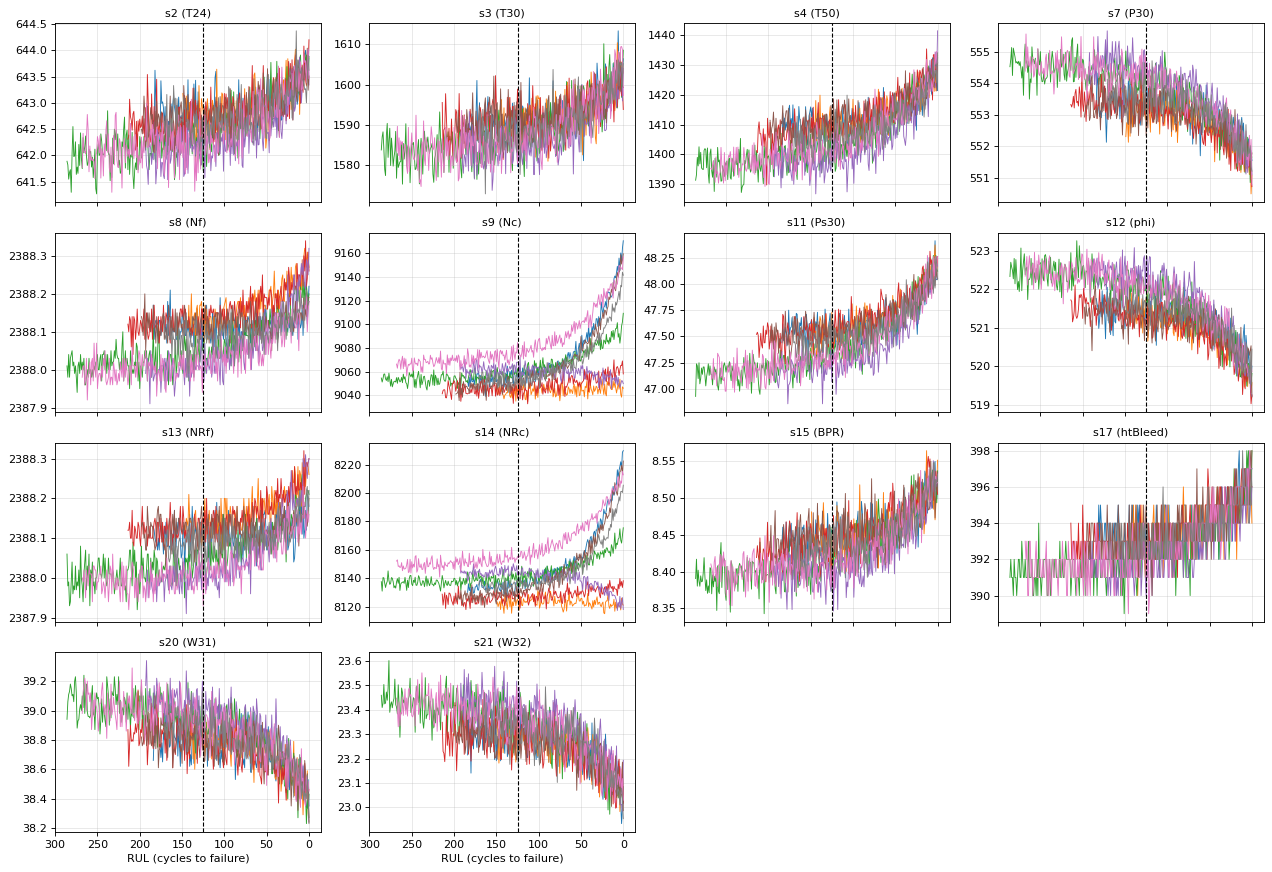

In [8]:
# Sensors aligned at failure: x = RUL (counting down), so the right edge is the failure point.
fig, axes = plt.subplots(4, 4, figsize=(16, 11), sharex=True)
for ax, col in zip(axes.ravel(), kept):
    for u in show_units:
        g = train_l[train_l.unit == u]
        ax.plot(g.RUL, g[col], lw=0.8)
    ax.axvline(125, color="k", ls="--", lw=1)
    ax.set_title(f"{col} ({SENSOR_INFO[col][0]})", fontsize=10)
for ax in axes.ravel()[len(kept):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("RUL (cycles to failure)")
axes[0, 0].invert_xaxis()           # shared x: one inversion flips all panels
plt.tight_layout(); plt.show()

### 4.2 Estimating the onset per engine

`degradation_onset` estimates, for each engine, the cycle from which the sensors stay outside their own early-life range (details and settings in the docstring). It is an **estimate that depends on its settings**, not ground truth; the sensitivity table shows how much.

Onset detected in 100 of 100 engines
count    100.0
mean     136.5
std       40.9
min       68.0
25%      111.0
50%      129.5
75%      156.2
max      259.0
Correlation between engine life and RUL at onset: 0.93


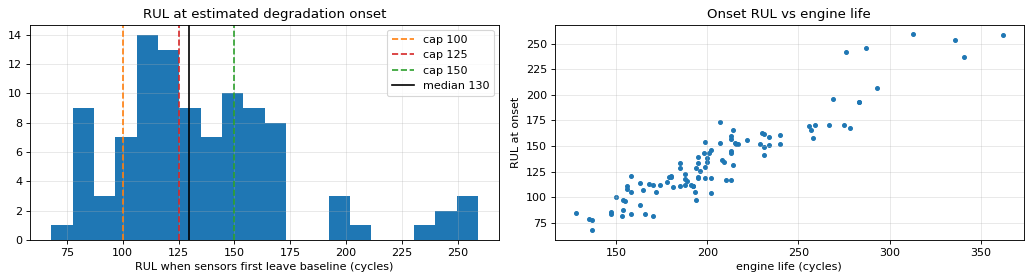

In [9]:
onset = degradation_onset(train, kept, baseline=30, k=3.0, window=10, persist=10)
s = onset.rul_at_onset.dropna()
print(f"Onset detected in {len(s)} of {len(onset)} engines")
print(s.describe().round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].hist(s, bins=20)
for c, col in [(100, "C1"), (125, "C3"), (150, "C2")]:
    ax[0].axvline(c, color=col, ls="--", label=f"cap {c}")
ax[0].axvline(s.median(), color="k", label=f"median {s.median():.0f}")
ax[0].set(title="RUL at estimated degradation onset", xlabel="RUL when sensors first leave baseline (cycles)"); ax[0].legend()

ax[1].scatter(onset.life, s, s=12)
ax[1].set(title="Onset RUL vs engine life", xlabel="engine life (cycles)", ylabel="RUL at onset")
plt.tight_layout(); plt.show()
print("Correlation between engine life and RUL at onset: %.2f" % np.corrcoef(onset.life.loc[s.index], s)[0, 1])

In [10]:
rows = []
for base in (20, 30, 40):
    for k in (2.0, 3.0, 4.0):
        o = degradation_onset(train, kept, baseline=base, k=k).rul_at_onset.dropna()
        rows.append({"baseline": base, "k": k, "detected": len(o), "q10": o.quantile(.1), "q25": o.quantile(.25), "median": o.median(), "q75": o.quantile(.75)})
sens = pd.DataFrame(rows).round(0).astype({"detected": int})
display(sens)
print(f"Median RUL-at-onset ranges from {sens['median'].min():.0f} to {sens['median'].max():.0f} across these settings.")

Median RUL-at-onset ranges from 116 to 139 across these settings.


,baseline,k,detected,q10,q25,median,q75
0,20,2.0,100,106.0,119.0,139.0,168.0
1,20,3.0,100,91.0,110.0,132.0,156.0
2,20,4.0,100,86.0,97.0,118.0,148.0
3,30,2.0,100,102.0,118.0,139.0,166.0
4,30,3.0,100,88.0,111.0,130.0,156.0
5,30,4.0,100,83.0,98.0,118.0,145.0
6,40,2.0,100,99.0,117.0,137.0,162.0
7,40,3.0,100,85.0,108.0,124.0,153.0
8,40,4.0,100,81.0,95.0,116.0,144.0


**Findings**
- At the default settings the median RUL at onset is about 130 cycles (interquartile range about 111 to 156). Across the nine settings tried, the median ranges from 116 to 139.
- Onset RUL grows strongly with engine life (correlation 0.93 at the default settings): long-lived engines show degradation far earlier than 125 cycles before failure, and short-lived ones later. **No single cap suits every engine.**

In [11]:
# Within-engine trend vs pooled correlation with RUL: large gaps point to between-engine offsets (initial wear).
pooled = train_l[kept + ["RUL"]].corr(method="spearman")["RUL"].drop("RUL").abs()
cmp_ = pd.DataFrame({"within-engine |rho| vs cycle": report.loc[kept, "trend_strength"], "pooled |rho| vs RUL": pooled}).round(2)
cmp_["gap"] = (cmp_.iloc[:, 0] - cmp_.iloc[:, 1]).round(2)
display(cmp_.sort_values("gap", ascending=False))

,within-engine |rho| vs cycle,pooled |rho| vs RUL,gap
s14,0.77,0.20,0.57
s9,0.75,0.32,0.43
s8,0.77,0.57,0.20
s13,0.76,0.57,0.19
s12,0.81,0.69,0.12
s11,0.82,0.72,0.10
s7,0.77,0.68,0.09
s4,0.78,0.70,0.08
s20,0.71,0.65,0.06
s15,0.72,0.67,0.05


For `s14` and `s9` the within-engine trend is strong (0.77, 0.75) but the pooled correlation with RUL is weak (0.20, 0.32). That means engines differ a lot in their starting level, so one raw reading cannot separate initial wear from degradation. **Hypothesis to test in Phase 3/4 (not a conclusion):** features relative to each engine's own early baseline, or windows that capture slope, may help.

Share of training rows whose target sits on the flat part of the capped curve (RUL >= 125): 39.4%
Shortest training life: 128 cycles  |  engines with life <= 125: 0
Test engines whose true RUL exceeds the cap: 11 of 100


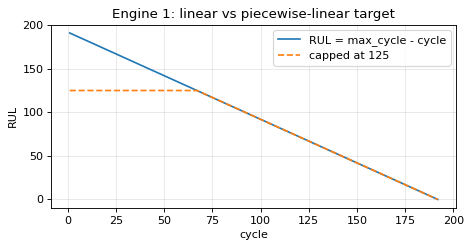

In [12]:
CAP = 125
frac_flat = (train_l.RUL >= CAP).mean()
print(f"Share of training rows whose target sits on the flat part of the capped curve (RUL >= {CAP}): {frac_flat:.1%}")
print(f"Shortest training life: {life.min()} cycles  |  engines with life <= {CAP}: {(life <= CAP).sum()}")
print(f"Test engines whose true RUL exceeds the cap: {(test_rul > CAP).sum()} of {len(test_rul)}")

u = train_l[train_l.unit == 1]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(u.cycle, u.RUL, label="RUL = max_cycle - cycle"); ax.plot(u.cycle, u.RUL_capped, label=f"capped at {CAP}", ls="--")
ax.set(title="Engine 1: linear vs piecewise-linear target", xlabel="cycle", ylabel="RUL"); ax.legend()
plt.tight_layout(); plt.show()

**Decision (provisional).** Use `CAP = 125`.

- *Evidence for it:* it sits inside the range of median onset RULs (116 to 139) found above, and it is shorter than every training life (minimum 128), so every engine has a flat segment followed by a falling one.
- *What it costs:* 39.4% of training rows lie on the flat part, and 11 of 100 test engines have a true RUL above the cap. State in the report which RUL (capped or the uncapped file values) the test metrics use; the official `RUL_FD001.txt` is uncapped.
- *Status:* the cap is a modelling choice, not a measured constant. It will be **swept (for example 100 to 150) with engine-grouped cross-validation in Phase 4**, and the final value chosen on that evidence, never on the test set.

## 5. Summary

| Item | Outcome |
|---|---|
| Data check | 100 train / 100 test engines, 26 columns, 100 true RUL values, all validated by the loader |
| Columns kept | 14 sensors (`s2, s3, s4, s7, s8, s9, s11, s12, s13, s14, s15, s17, s20, s21`); settings and 6 other sensors dropped |
| Labels | `RUL = max_cycle - cycle`; capped target `min(RUL, 125)` (provisional) |
| Window length | at most 30 cycles needs no padding (shortest test engine has 31 cycles) |

**Limitations to carry into the report**
- Simulated data from one fault mode and one operating condition; nothing here says how a method behaves on FD002-FD004 or on real engines.
- The sensor-name mapping is the usual convention, not stated by the readme.
- The onset analysis is an estimate that depends on its settings.
- All statistics above use training data only; the test data was used only for the descriptive counts in section 1.